## Import Libraries

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split, cross_val_score, KFold,
    GridSearchCV, RandomizedSearchCV
)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Models
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor, AdaBoostRegressor, GradientBoostingRegressor
)

# Optional model: install xgboost if this import fails
try:
    from xgboost import XGBRegressor
    xgboost_available = True
except ImportError:
    xgboost_available = False
    print("XGBoost is not installed. To use it, run: !pip install xgboost")

RANDOM_STATE = 42

## Load Dataset

In [21]:
df = pd.read_csv("/content/data.csv", low_memory=False)

print("Dataset shape:", df.shape)
display(df.head())
print(df.columns.tolist())

Dataset shape: (6405008, 18)


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge
0,1.0,2020-01-01 00:28:15,2020-01-01 00:33:03,1.0,1.2,1.0,N,238,239,1.0,6.0,3.0,0.5,1.47,0.0,0.3,11.27,2.5
1,1.0,2020-01-01 00:35:39,2020-01-01 00:43:04,1.0,1.2,1.0,N,239,238,1.0,7.0,3.0,0.5,1.50,0.0,0.3,12.30,2.5
2,1.0,2020-01-01 00:47:41,2020-01-01 00:53:52,1.0,0.6,1.0,N,238,238,1.0,6.0,3.0,0.5,1.00,0.0,0.3,10.80,2.5
3,1.0,2020-01-01 00:55:23,2020-01-01 01:00:14,1.0,0.8,1.0,N,238,151,1.0,5.5,0.5,0.5,1.36,0.0,0.3,8.16,0.0
4,2.0,2020-01-01 00:01:58,2020-01-01 00:04:16,1.0,0.0,1.0,N,193,193,2.0,3.5,0.5,0.5,0.00,0.0,0.3,4.80,0.0


['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'store_and_fwd_flag', 'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge']


## Data Cleaning

In [22]:
# Check missing values and duplicates before cleaning
print("Missing values (top 10):")
display(df.isnull().sum().sort_values(ascending=False).head(10))
print("Duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates().copy()

# Convert important columns to numeric where available
numeric_columns = [
    "VendorID", "passenger_count", "trip_distance",
    "PULocationID", "DOLocationID", "RatecodeID", "total_amount"
]
for col in numeric_columns:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

df["tpep_pickup_datetime"] = pd.to_datetime(
    df["tpep_pickup_datetime"], errors="coerce"
)

# Remove rows where target or pickup time is missing
df = df.dropna(subset=["total_amount", "tpep_pickup_datetime"])

# Remove clearly invalid target/distance values
df = df[(df["total_amount"] > 0) & (df["trip_distance"] > 0)].copy()
df = df[df["total_amount"] <= 500].copy()

# Optional broad distance filter to remove obvious data errors
df = df[df["trip_distance"] <= 100].copy()

# Keep the original notebook's small-sample approach so the models run faster.
# Increase 1000 to 5000 or 10000 later if your computer/runtime can handle it.
df = df.sample(n=min(1000, len(df)), random_state=42).copy()

print("Shape after cleaning and sampling:", df.shape)

Missing values (top 10):


,0
VendorID,65441
passenger_count,65441
payment_type,65441
RatecodeID,65441
store_and_fwd_flag,65441
tpep_pickup_datetime,0
trip_distance,0
tpep_dropoff_datetime,0
PULocationID,0
DOLocationID,0


Duplicate rows: 12949
Shape after cleaning and sampling: (1000, 18)


## Feature Engineering

In [23]:
# Extract information available from pickup time only
df["pickup_hour"] = df["tpep_pickup_datetime"].dt.hour
df["pickup_day"] = df["tpep_pickup_datetime"].dt.dayofweek
df["pickup_month"] = df["tpep_pickup_datetime"].dt.month

# Fill missing passenger count with NaN for later imputation
if "passenger_count" not in df.columns:
    df["passenger_count"] = np.nan

display(df[["tpep_pickup_datetime", "pickup_hour", "pickup_day",
            "pickup_month", "trip_distance", "total_amount"]].head())

,tpep_pickup_datetime,pickup_hour,pickup_day,pickup_month,trip_distance,total_amount
3753311,2020-01-19 21:11:06,21,6,1,2.58,19.56
2023204,2020-01-11 17:04:58,17,5,1,16.45,73.70
2985340,2020-01-16 10:50:24,10,3,1,6.53,26.80
1745659,2020-01-10 12:30:16,12,4,1,2.50,17.15
2190227,2020-01-12 13:45:20,13,6,1,10.90,61.42


## Feature Selection

In [24]:
# Do NOT include fare_amount, tip_amount, tolls_amount, taxes,
# improvement_surcharge, congestion_surcharge, or other bill components.
# These can leak information about total_amount into the model.

candidate_features = [
    "passenger_count", "trip_distance",
    "pickup_hour", "pickup_day", "pickup_month"
]


X = df[candidate_features].copy()
y = df["total_amount"].copy()

print("Features used:", X.columns.tolist())
print("Target: total_amount")
print("Rows available:", len(X))

Features used: ['passenger_count', 'trip_distance', 'pickup_hour', 'pickup_day', 'pickup_month']
Target: total_amount
Rows available: 1000


## Train-Test Split

In [25]:
# Use a sample only if needed for a faster run.
# Example: df = df.sample(10000, random_state=42) before feature selection.
# By default, this notebook uses all cleaned rows.

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 800
Testing rows: 200


## Preprocessing and Scaling

In [26]:
# Put imputation and scaling inside a Pipeline.
# This way, preprocessing is fitted only on each training fold during cross-validation.
def make_pipeline(model):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", model)
    ])

kf = KFold(n_splits=5, shuffle=True, random_state=42)

## Evaluation Function

In [27]:
def evaluate(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)

    print(f"\n{name}")
    print("MAE:", round(mae, 4))
    print("MSE:", round(mse, 4))
    print("RMSE:", round(rmse, 4))
    print("R2:", round(r2, 4))

    return {"Model": name, "MAE": mae, "MSE": mse, "RMSE": rmse, "R2": r2}

## Training Models

In [28]:
# Start with a simple baseline so we can check whether ML models improve on it.
models = {
    "Baseline": DummyRegressor(strategy="median"),
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(),
    "Lasso": Lasso(max_iter=10000),
    "SVR Linear": SVR(kernel="linear"),
    "SVR RBF": SVR(kernel="rbf"),
    "KNN": KNeighborsRegressor(),
    "Decision Tree": DecisionTreeRegressor(max_depth=10, random_state=42),
    "Random Forest": RandomForestRegressor(
        n_estimators=100, max_depth=15, random_state=42, n_jobs=-1
    ),
    "AdaBoost": AdaBoostRegressor(random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42)
}

if xgboost_available:
    models["XGBoost"] = XGBRegressor(
        n_estimators=100, max_depth=5, learning_rate=0.1,
        random_state=42, n_jobs=-1
    )

trained_models = {}
results = []

for name, estimator in models.items():
    print("\n" + "=" * 50)
    model = make_pipeline(estimator)
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    result = evaluate(name, y_test, predictions)
    results.append(result)
    trained_models[name] = model

results_df = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
display(results_df)



Baseline
MAE: 7.7164
MSE: 210.0924
RMSE: 14.4946
R2: -0.0677


Linear Regression
MAE: 2.7839
MSE: 30.7716
RMSE: 5.5472
R2: 0.8436


Ridge
MAE: 2.7837
MSE: 30.7297
RMSE: 5.5434
R2: 0.8438


Lasso
MAE: 2.7992
MSE: 29.4907
RMSE: 5.4305
R2: 0.8501


SVR Linear
MAE: 2.7346
MSE: 29.3448
RMSE: 5.4171
R2: 0.8509


SVR RBF
MAE: 4.1986
MSE: 74.1339
RMSE: 8.6101
R2: 0.6232


KNN
MAE: 3.7509
MSE: 42.3447
RMSE: 6.5073
R2: 0.7848


Decision Tree
MAE: 3.3958
MSE: 39.3234
RMSE: 6.2708
R2: 0.8002


Random Forest
MAE: 2.8966
MSE: 26.4499
RMSE: 5.1429
R2: 0.8656


AdaBoost
MAE: 3.8085
MSE: 38.4235
RMSE: 6.1987
R2: 0.8047


Gradient Boosting
MAE: 2.7964
MSE: 29.2938
RMSE: 5.4124
R2: 0.8511


XGBoost
MAE: 2.7894
MSE: 28.5755
RMSE: 5.3456
R2: 0.8548


,Model,MAE,MSE,RMSE,R2
0,Random Forest,2.896602,26.449909,5.142948,0.865581
1,XGBoost,2.789371,28.575451,5.345601,0.854779
2,Gradient Boosting,2.796423,29.293757,5.412371,0.851128
3,SVR Linear,2.734570,29.344797,5.417084,0.850869
4,Lasso,2.799172,29.490710,5.430535,0.850128
5,Ridge,2.783716,30.729680,5.543436,0.843831
6,Linear Regression,2.783935,30.771552,5.547211,0.843618
7,AdaBoost,3.808528,38.423451,6.198665,0.804731
8,Decision Tree,3.395763,39.323449,6.270841,0.800157
9,KNN,3.750910,42.344678,6.507279,0.784803


## K-Fold Cross-Validation

In [29]:
# Compare models using training data only.
# Lower CV RMSE is better. The test set is kept for final evaluation.
cv_results = []

for name, estimator in models.items():
    pipeline = make_pipeline(estimator)
    scores = cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=kf,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1
    )
    cv_rmse = -scores
    cv_results.append({
        "Model": name,
        "CV_RMSE_Mean": cv_rmse.mean(),
        "CV_RMSE_Std": cv_rmse.std()
    })
    print(f"{name}: CV RMSE = {cv_rmse.mean():.4f} +/- {cv_rmse.std():.4f}")

cv_results_df = pd.DataFrame(cv_results).sort_values("CV_RMSE_Mean").reset_index(drop=True)
display(cv_results_df)

Baseline: CV RMSE = 19.7548 +/- 8.6514
Linear Regression: CV RMSE = 6.2790 +/- 2.7134
Ridge: CV RMSE = 6.2757 +/- 2.7219
Lasso: CV RMSE = 6.2606 +/- 3.0965
SVR Linear: CV RMSE = 5.9762 +/- 2.9553
SVR RBF: CV RMSE = 15.6646 +/- 9.6757
KNN: CV RMSE = 10.3044 +/- 7.6090
Decision Tree: CV RMSE = 10.1411 +/- 3.7219
Random Forest: CV RMSE = 7.9652 +/- 5.2979
AdaBoost: CV RMSE = 9.0181 +/- 4.5674
Gradient Boosting: CV RMSE = 8.3569 +/- 4.6531
XGBoost: CV RMSE = 10.3174 +/- 5.0269


,Model,CV_RMSE_Mean,CV_RMSE_Std
0,SVR Linear,5.976217,2.955336
1,Lasso,6.260552,3.096496
2,Ridge,6.275702,2.721867
3,Linear Regression,6.278955,2.713421
4,Random Forest,7.965217,5.297886
5,Gradient Boosting,8.356869,4.653135
6,AdaBoost,9.018052,4.567439
7,Decision Tree,10.141093,3.721864
8,KNN,10.304432,7.608998
9,XGBoost,10.317437,5.026858


## Grid Search

In [30]:
# Tune selected models rather than running expensive searches on every model.
ridge_grid = GridSearchCV(
    make_pipeline(Ridge()),
    param_grid={"model__alpha": [0.1, 1, 10, 100]},
    scoring="neg_root_mean_squared_error",
    cv=kf,
    n_jobs=-1
)
ridge_grid.fit(X_train, y_train)
print("Best Ridge parameters:", ridge_grid.best_params_)
print("Best Ridge CV RMSE:", -ridge_grid.best_score_)

rf_grid = GridSearchCV(
    make_pipeline(RandomForestRegressor(random_state=42, n_jobs=-1)),
    param_grid={
        "model__n_estimators": [100, 150],
        "model__max_depth": [10, 15, None],
        "model__min_samples_leaf": [1, 2]
    },
    scoring="neg_root_mean_squared_error",
    cv=3,  # fewer folds to keep runtime reasonable
    n_jobs=-1
)
rf_grid.fit(X_train, y_train)
print("Best Random Forest parameters:", rf_grid.best_params_)
print("Best Random Forest CV RMSE:", -rf_grid.best_score_)

Best Ridge parameters: {'model__alpha': 10}
Best Ridge CV RMSE: 6.251357909741005
Best Random Forest parameters: {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 150}
Best Random Forest CV RMSE: 8.330534938945728


## Random Search

In [31]:
# Randomized search is another option. This small search is kept for demonstration.
rand_ridge = RandomizedSearchCV(
    make_pipeline(Ridge()),
    param_distributions={"model__alpha": [0.01, 0.1, 1, 10, 100, 1000]},
    n_iter=5,
    scoring="neg_root_mean_squared_error",
    cv=3,
    random_state=42,
    n_jobs=-1
)
rand_ridge.fit(X_train, y_train)

print("Random Search Ridge parameters:", rand_ridge.best_params_)
print("Random Search Ridge CV RMSE:", -rand_ridge.best_score_)

Random Search Ridge parameters: {'model__alpha': 1}
Random Search Ridge CV RMSE: 6.695374501234096


## Compare Tuned Models and Select Best Model

In [32]:
# Include tuned models in the final comparison.
candidate_models = dict(trained_models)
candidate_models["Tuned Ridge"] = ridge_grid.best_estimator_
candidate_models["Tuned Random Forest"] = rf_grid.best_estimator_

# Select using training cross-validation scores, not test scores.
final_cv_rows = []
for name, model in candidate_models.items():
    scores = cross_val_score(
        model, X_train, y_train,
        cv=3,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1
    )
    final_cv_rows.append({
        "Model": name,
        "CV_RMSE_Mean": (-scores).mean(),
        "CV_RMSE_Std": (-scores).std()
    })

final_cv_df = pd.DataFrame(final_cv_rows).sort_values("CV_RMSE_Mean").reset_index(drop=True)
display(final_cv_df)

best_model_name = final_cv_df.loc[0, "Model"]
best_model = candidate_models[best_model_name]
best_model.fit(X_train, y_train)

print("Best model based on training cross-validation:", best_model_name)

,Model,CV_RMSE_Mean,CV_RMSE_Std
0,SVR Linear,6.095571,2.018416
1,Lasso,6.652936,2.044651
2,Tuned Ridge,6.657150,1.641257
3,Ridge,6.695375,1.471468
4,Linear Regression,6.700376,1.452642
5,Tuned Random Forest,8.330535,4.159358
6,Random Forest,8.451014,4.303522
7,Gradient Boosting,9.193685,2.518422
8,AdaBoost,9.697977,2.267440
9,XGBoost,10.006085,3.295364


Best model based on training cross-validation: SVR Linear


## Final Test Evaluation

In [33]:
# Evaluate the selected model once on the held-out test set.
best_predictions = best_model.predict(X_test)
best_result = evaluate(best_model_name + " (Test Set)", y_test, best_predictions)


SVR Linear (Test Set)
MAE: 2.7346
MSE: 29.3448
RMSE: 5.4171
R2: 0.8509


## Visualization: Actual vs Predicted

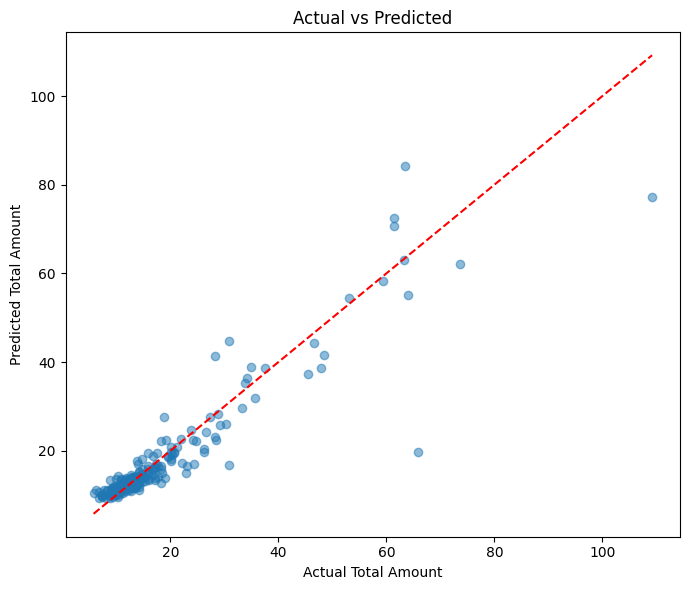

In [34]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, best_predictions, alpha=0.5)
low = min(y_test.min(), best_predictions.min())
high = max(y_test.max(), best_predictions.max())
plt.plot([low, high], [low, high], linestyle="--", color="red")
plt.xlabel("Actual Total Amount")
plt.ylabel("Predicted Total Amount")
plt.title("Actual vs Predicted")
plt.tight_layout()
plt.show()

## Visualization: Model Comparison

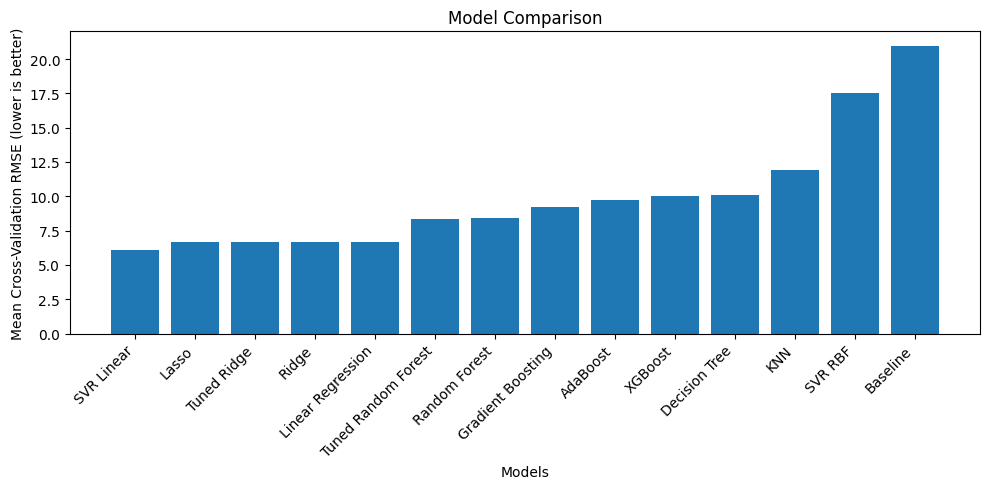

In [35]:
plt.figure(figsize=(10, 5))
plot_df = final_cv_df.sort_values("CV_RMSE_Mean")
plt.bar(plot_df["Model"], plot_df["CV_RMSE_Mean"])
plt.xlabel("Models")
plt.ylabel("Mean Cross-Validation RMSE (lower is better)")
plt.title("Model Comparison")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Overfitting Check

In [36]:
train_predictions = best_model.predict(X_train)
test_predictions = best_model.predict(X_test)

print("Train R2:", round(r2_score(y_train, train_predictions), 4))
print("Test R2:", round(r2_score(y_test, test_predictions), 4))
print("Train RMSE:", round(np.sqrt(mean_squared_error(y_train, train_predictions)), 4))
print("Test RMSE:", round(np.sqrt(mean_squared_error(y_test, test_predictions)), 4))

Train R2: 0.9058
Test R2: 0.8509
Train RMSE: 6.4535
Test RMSE: 5.4171


## Residual Analysis

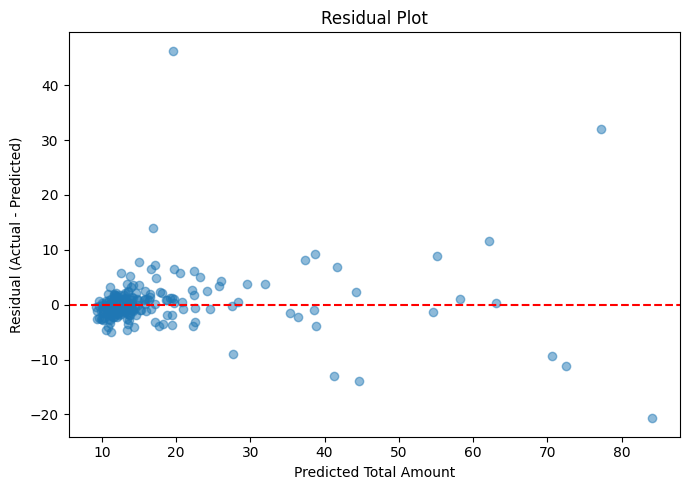

In [37]:
residuals = y_test - best_predictions

plt.figure(figsize=(7, 5))
plt.scatter(best_predictions, residuals, alpha=0.5)
plt.axhline(0, linestyle="--", color="red")
plt.xlabel("Predicted Total Amount")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residual Plot")
plt.tight_layout()
plt.show()

## Prediction on New Data

In [38]:

print("Enter trip details below to predict the estimated total taxi amount.")

# Ask the user for values interactively
passenger_count = int(input("Number of passengers: "))
trip_distance = float(input("Estimated trip distance (miles): "))
pickup_hour = int(input("Pickup hour (0-23): "))
pickup_day = int(input("Pickup day of week (0=Monday, 6=Sunday): "))
pickup_month = int(input("Pickup month (1-12): "))

# Validate inputs
if passenger_count < 1:
    raise ValueError("Number of passengers must be at least 1.")

if trip_distance <= 0:
    raise ValueError("Trip distance must be greater than 0.")

if not 0 <= pickup_hour <= 23:
    raise ValueError("Pickup hour must be between 0 and 23.")

if not 0 <= pickup_day <= 6:
    raise ValueError("Pickup day must be between 0 (Monday) and 6 (Sunday).")

if not 1 <= pickup_month <= 12:
    raise ValueError("Pickup month must be between 1 and 12.")

# Create prediction data using the same five features as training
new_trip_df = pd.DataFrame([{
    "passenger_count": passenger_count,
    "trip_distance": trip_distance,
    "pickup_hour": pickup_hour,
    "pickup_day": pickup_day,
    "pickup_month": pickup_month
}])

# Ensure feature order matches training
new_trip_df = new_trip_df[X.columns]

# Predict total taxi amount
predicted_amount = float(best_model.predict(new_trip_df)[0])

print("\n" + "=" * 45)
print(f"Estimated taxi total amount: ${predicted_amount:.2f}")
print("=" * 45)

Enter trip details below to predict the estimated total taxi amount.
Number of passengers: 4
Estimated trip distance (miles): 20
Pickup hour (0-23): 6
Pickup day of week (0=Monday, 6=Sunday): 5
Pickup month (1-12): 7

Estimated taxi total amount: $75.81
